<a href="https://colab.research.google.com/github/Csahoo009/ML-for-DA/blob/main/T9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)
from google.colab import files

uploaded = files.upload()

# 1. Load dataset
df = pd.read_csv("indian_house_prices.csv")

# 2. Convert Price to ₹ Lakhs for readability
df["Price_Lakhs"] = df["Price"] / 100000.0

print(f"Dataset Loaded: {df.shape[0]} rows, {df.shape[1]} columns")
print(df[["Area", "Price_Lakhs", "No. of Bedrooms", "Gymnasium", "Resale"]].head())

Saving indian_house_prices.csv to indian_house_prices.csv
Dataset Loaded: 32963 rows, 42 columns
   Area  Price_Lakhs  No. of Bedrooms  Gymnasium  Resale
0  3340       300.00                4          1       0
1  1045        78.88                2          1       0
2  1179        48.66                2          1       0
3  1675        83.58                3          0       0
4  1670        68.45                3          1       0


In [3]:
# Select features and binary target ('Resale': 0 = New, 1 = Resale)
features = ['Area', 'Price_Lakhs', 'No. of Bedrooms', 'Gymnasium', 'SwimmingPool']
target = 'Resale'

X = df[features].fillna(df[features].mean())
y = df[target]

# Train-Test Split (80% Train, 20% Test) with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling (Crucial for SVM hyperplane optimization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training Samples: {X_train_scaled.shape[0]}")
print(f"Testing Samples : {X_test_scaled.shape[0]}")

Training Samples: 26370
Testing Samples : 6593


In [4]:
# To prevent high execution wait times on 32k+ records, we fit on a sample of 5,000 records
sample_size = 5000
X_train_sub = X_train_scaled[:sample_size]
y_train_sub = y_train[:sample_size]

# Initialize Support Vector Classifier with RBF kernel
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)

# Train the SVM model
svm_model.fit(X_train_sub, y_train_sub)

print("SVM Model Training Complete!")
print(f"Number of Support Vectors per class: {svm_model.n_support_}")

SVM Model Training Complete!
Number of Support Vectors per class: [1768 1738]


In [5]:
# Predict on the full test dataset
y_pred_svm = svm_model.predict(X_test_scaled)

# Calculate Evaluation Metrics
acc = accuracy_score(y_test, y_pred_svm)
prec = precision_score(y_test, y_pred_svm, average='weighted', zero_division=0)
rec = recall_score(y_test, y_pred_svm, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_pred_svm, average='weighted', zero_division=0)
cm = confusion_matrix(y_test, y_pred_svm)

print("=== SVM PERFORMANCE METRICS ===")
print(f"Accuracy  : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}\n")

print("Confusion Matrix:")
print(cm)

print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred_svm, target_names=["New (0)", "Resale (1)"], zero_division=0))

=== T9: SVM PERFORMANCE METRICS ===
Accuracy  : 0.6625 (66.25%)
Precision : 0.6608
Recall    : 0.6625
F1-Score  : 0.6122

Confusion Matrix:
[[3759  319]
 [1906  609]]

Detailed Classification Report:
              precision    recall  f1-score   support

     New (0)       0.66      0.92      0.77      4078
  Resale (1)       0.66      0.24      0.35      2515

    accuracy                           0.66      6593
   macro avg       0.66      0.58      0.56      6593
weighted avg       0.66      0.66      0.61      6593



5-Fold CV Accuracy Scores: [0.651 0.664 0.66  0.665 0.659]
Mean CV Accuracy         : 0.6598



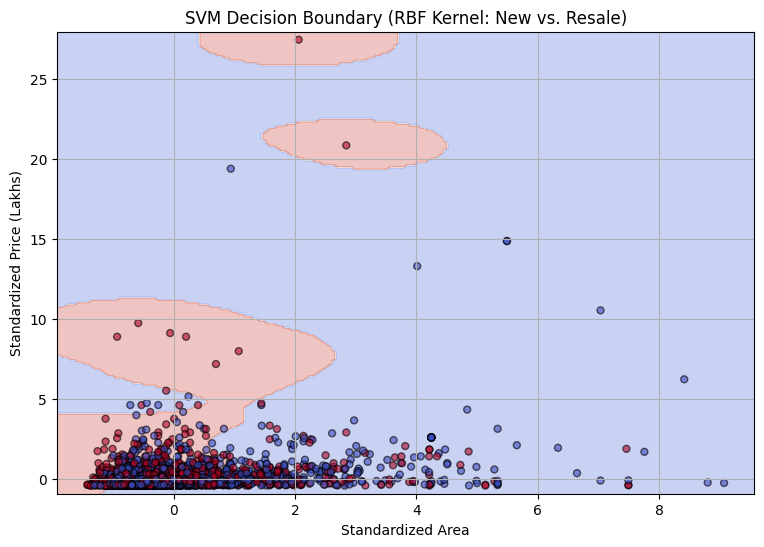

In [6]:
# 1. 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(svm_model, X_train_sub, y_train_sub, cv=cv, scoring='accuracy')

print(f"5-Fold CV Accuracy Scores: {np.round(cv_scores, 4)}")
print(f"Mean CV Accuracy         : {cv_scores.mean():.4f}\n")

# 2. Visualizing SVM Decision Boundary using 2 Main Features: Area vs Price
X_vis = X_train_sub[:, :2] # Area and Price_Lakhs (scaled)
y_vis = y_train_sub.values

vis_model = SVC(kernel='rbf', C=1.0)
vis_model.fit(X_vis, y_vis)

# Create a mesh grid
x_min, x_max = X_vis[:, 0].min() - 0.5, X_vis[:, 0].max() + 0.5
y_min, y_max = X_vis[:, 1].min() - 0.5, X_vis[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))

Z = vis_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X_vis[:, 0], X_vis[:, 1], c=y_vis, cmap=plt.cm.coolwarm, edgecolors='k', alpha=0.6, s=25)
plt.xlabel("Standardized Area")
plt.ylabel("Standardized Price (Lakhs)")
plt.title("SVM Decision Boundary (RBF Kernel: New vs. Resale)")
plt.grid(True)
plt.show()